In [1]:

import os
from matplotlib import pyplot as plt
import numpy as np
from aotools.turbulence import infinitephasescreen,phasescreen
import random
import time
from numpy import fft


In [2]:
os.getcwd()
os.chdir("C:\\Users\\gqmc62\\OneDrive - Durham University\\Documents\\PhD\\")
os.getcwd()
os.chdir("soapy-master\soapy-master")
os.getcwd()

'C:\\Users\\gqmc62\\OneDrive - Durham University\\Documents\\PhD\\soapy-master\\soapy-master'

In [3]:
import soapy


In [4]:
sim=soapy.Sim("conf\SH_8x8.yaml")
sim.aoinit()
sim.makeIMat()
sim.aoloop()
#!soapy -g SH_8x8.yaml

Starting Sim: 2023-05-09-15-23-05
Pixel Scale: 12.50 pxls/m
subScreenSize: 102 simulation pixels
Creating mask...
Turbulence summary @ 500 nm:
| r0 = 0.16 m (0.64" seeing)
| Vbar_5/3 = 11.78 m/s
| tau0 = 4.26 ms
Initialise Infinite Phase Screen 1
Initialise Infinite Phase Screen 2
Initialise Infinite Phase Screen 3
Initialise Infinite Phase Screen 4
Initialising WFSs....
WFS 0: 104 measurements
Initialising 2 DMs...
Making DM Influence Functions...
DM 0: 2 active actuators
Making DM Influence Functions...
DM 1: 81 active actuators
83 total DM Actuators
Initialising Reconstructor...
Initialising 1 Science Cams...
Initialise Data Storage...
Initialisation Complete!
Making interaction Matrices...
Creating Interaction Matrix for DM 0 
2 of 2: Generating 2 Actuator DM iMat
Checking for redundant actuators...
DM 0 has 2 valid actuators (0 dropped)
Creating Interaction Matrix for DM 1 
81 of 81: Generating 81 Actuator DM iMat
Checking for redundant actuators...
DM 1 has 81 valid actuators (0 

In [5]:
sim2=sim

In [6]:
scrn_size=sim2.atmos.scrn_size
pixel_scale=sim2.atmos.pixel_scale
scrnStrengths=sim2.atmos.scrnStrengths
L0s=sim2.atmos.L0s
windSpeeds=sim2.atmos.windSpeeds
looptime=sim2.atmos.looptime
windDirs=sim2.atmos.windDirs

print(scrn_size)
print(pixel_scale)
print(scrnStrengths)
print(L0s)


102
0.08
[0.24251463 0.32949376 0.6369715  0.6369715 ]
[20 20 20 20]


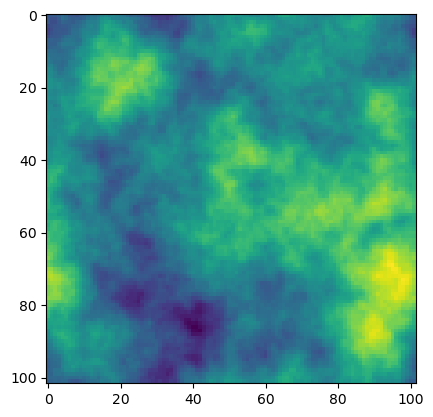

In [7]:
phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,scrnStrengths[-1],L0s[-1])
plt.imshow(phase_screen.scrn)

In [8]:
print(phase_screen)

In [9]:
phase_screen.make_initial_screen()

In [10]:
x=phasescreen.ft_phase_screen(scrnStrengths[-1],scrn_size,0.08,L0s[-1],1e-10)
print(scrn_size)

102


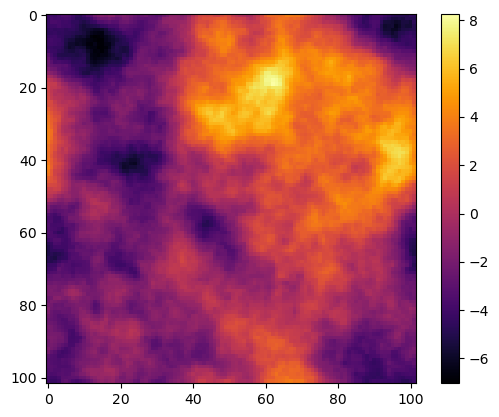

In [11]:
plt.imshow(x,cmap='inferno')
plt.colorbar()
plt.show()

In [12]:
def ift2(G, delta_f, FFT=None):
    """
    Wrapper for inverse fourier transform

    Parameters:
        G: data to transform
        delta_f: pixel seperation
        FFT (FFT object, optional): An accelerated FFT object
    """

    N = G.shape[0]

    if FFT:
        g = numpy.fft.fftshift(FFT(numpy.fft.fftshift(G))) * (N * delta_f) ** 2
    else:
        g = fft.ifftshift(fft.ifft2(fft.fftshift(G))) * (N * delta_f) ** 2

    return g


In [13]:
FFT=None
N=phase_screen.stencil_length
delta = 0.08
print(delta)
print(N)
r0 = float(scrnStrengths[-1])
L0 = float(L0s[-1])
l0 = float(1e-10)
R = random.SystemRandom(time.time())
seed = int(R.random()*100000)
np.random.seed(seed)
del_f = 1./(N*delta)
fx = np.arange(-N/2., N/2.) * del_f
(fx, fy) = np.meshgrid(fx,fx)
f = np.sqrt(fx**2. + fy**2.)
fm = 5.92/l0/(2*np.pi)
f0 = 1./L0
PSD_phi = (0.023*r0**(-5./3.) * np.exp(-1*((f/fm)**2)) / (((f**2) + (f0**2))**(11./6)))
PSD_phi[int(N/2), int(N/2)] = 0
cn = ((np.random.normal(size=(N, N))+1j * np.random.normal(size=(N, N))) * np.sqrt(PSD_phi)*del_f)
phs = ift2(cn, 1, FFT).real

0.08
102


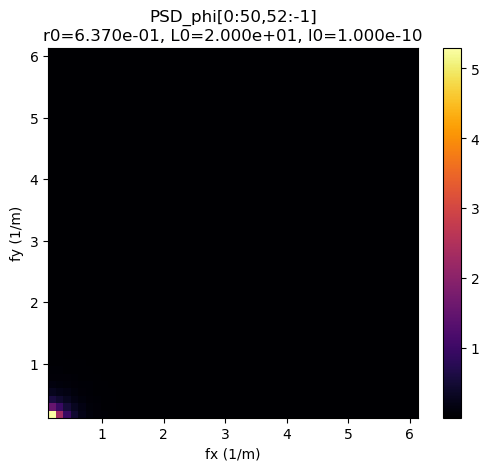

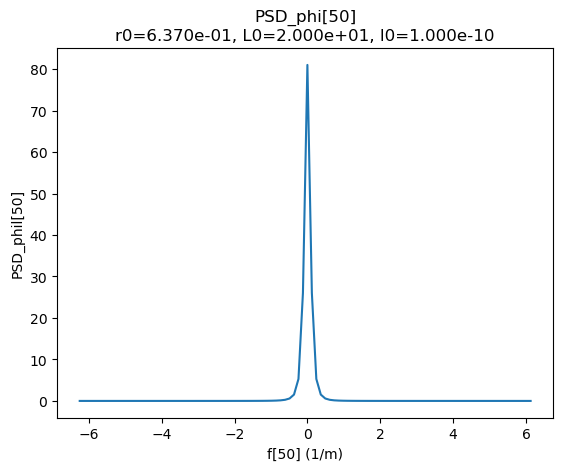

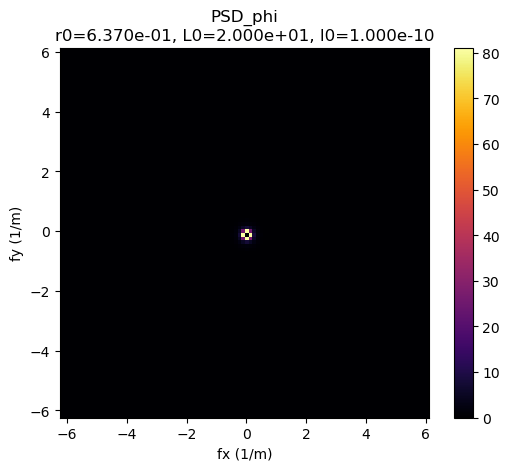

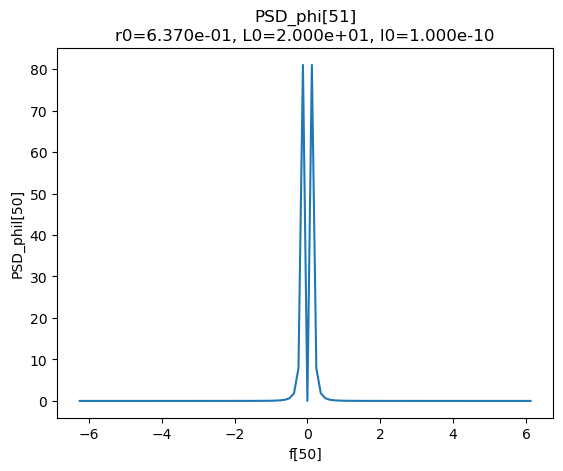

C:\Users\gqmc62\AppData\Local\Temp\ipykernel_7100\549632810.py:29: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(PSD_phi),cmap='inferno',extent=[fx[0,0],fx[-1,-1],fx[0,0],fx[-1,-1]])


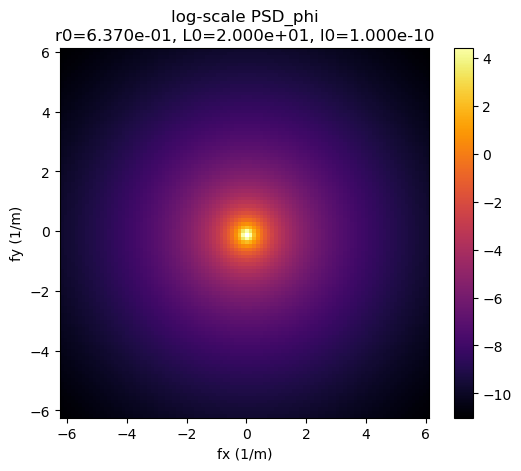

C:\Users\gqmc62\AppData\Local\Temp\ipykernel_7100\549632810.py:36: RuntimeWarning: divide by zero encountered in log
  plt.plot(fx[50],np.log(PSD_phi[51]),ls='-')


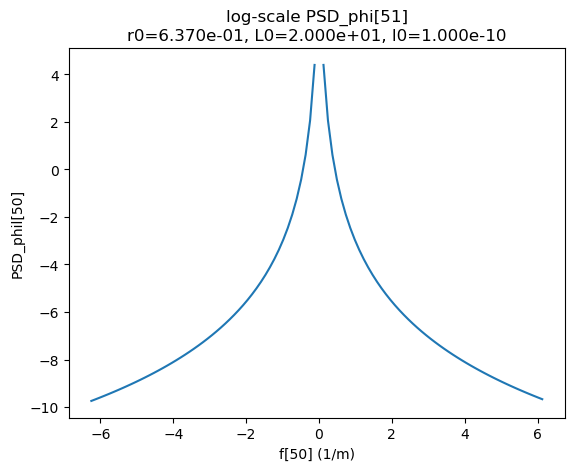

In [14]:
plt.imshow(PSD_phi[0:50,52:-1],cmap='inferno',extent=[fx[0,52],fx[0,-1],fx[50,52],fx[50,-1]])
plt.colorbar()
plt.xlabel('fx (1/m)')
plt.ylabel('fy (1/m)')
plt.title('PSD_phi[0:50,52:-1]\n'
          +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()
plt.plot(fx[50],PSD_phi[50],ls='-')
plt.xlabel('f[50] (1/m)')
plt.ylabel('PSD_phil[50]')
plt.title('PSD_phi[50]\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()

plt.imshow(PSD_phi,cmap='inferno',extent=[fx[0,0],fx[-1,-1],fx[0,0],fx[-1,-1]])
plt.colorbar()
plt.xlabel('fx (1/m)')
plt.ylabel('fy (1/m)')
plt.title('PSD_phi\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()
plt.plot(fx[50],PSD_phi[51],ls='-')
plt.xlabel('f[50]')
plt.ylabel('PSD_phil[50]')
plt.title('PSD_phi[51]\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()

plt.imshow(np.log(PSD_phi),cmap='inferno',extent=[fx[0,0],fx[-1,-1],fx[0,0],fx[-1,-1]])
plt.colorbar()
plt.xlabel('fx (1/m)')
plt.ylabel('fy (1/m)')
plt.title('log-scale PSD_phi\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()
plt.plot(fx[50],np.log(PSD_phi[51]),ls='-')
plt.xlabel('f[50] (1/m)')
plt.ylabel('PSD_phil[50]')
plt.title('log-scale PSD_phi[51]\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()

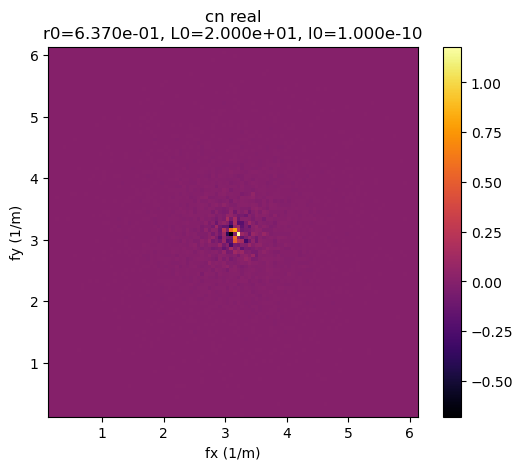

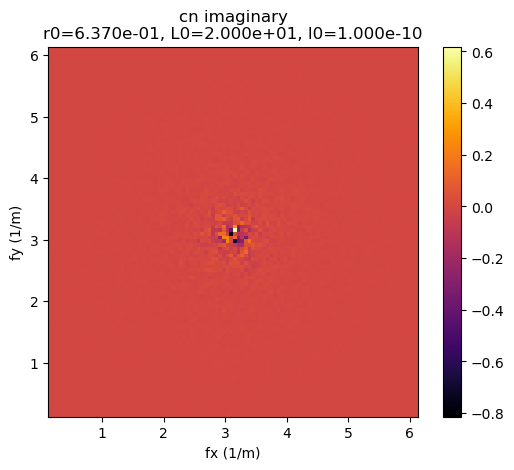

In [15]:
plt.imshow(cn.real,cmap='inferno',extent=[fx[0,52],fx[0,-1],fx[50,52],fx[50,-1]])
plt.colorbar()
plt.xlabel('fx (1/m)')
plt.ylabel('fy (1/m)')
plt.title('cn real\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()
plt.imshow(cn.imag,cmap='inferno',extent=[fx[0,52],fx[0,-1],fx[50,52],fx[50,-1]])
plt.colorbar()
plt.xlabel('fx (1/m)')
plt.ylabel('fy (1/m)')
plt.title('cn imaginary\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))
plt.show()

Text(0.5, 1.0, 'phs\nr0=6.370e-01, L0=2.000e+01, l0=1.000e-10')

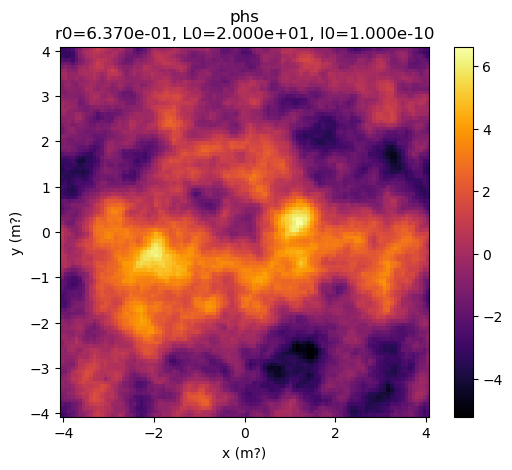

In [16]:
plt.imshow(phs,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.xlabel('x (m?)')
plt.ylabel('y (m?)')
plt.title('phs\n'
         +'r0={:.3e}, L0={:.3e}, l0={:.3e}'.format(r0,L0,l0))

In [17]:
print(phs.shape)
print(fx.shape)
print(fx)

(102, 102)
(102, 102)
[[-6.25       -6.12745098 -6.00490196 ...  5.88235294  6.00490196
   6.12745098]
 [-6.25       -6.12745098 -6.00490196 ...  5.88235294  6.00490196
   6.12745098]
 [-6.25       -6.12745098 -6.00490196 ...  5.88235294  6.00490196
   6.12745098]
 ...
 [-6.25       -6.12745098 -6.00490196 ...  5.88235294  6.00490196
   6.12745098]
 [-6.25       -6.12745098 -6.00490196 ...  5.88235294  6.00490196
   6.12745098]
 [-6.25       -6.12745098 -6.00490196 ...  5.88235294  6.00490196
   6.12745098]]


In [18]:
print(scrnStrengths)
print(L0s)

[0.24251463 0.32949376 0.6369715  0.6369715 ]
[20 20 20 20]


In [19]:
print(scrn_size)
print(pixel_scale)
print(scrn_size*pixel_scale)
print(1/scrn_size*pixel_scale)

102
0.08
8.16
0.000784313725490196


In [20]:
print(np.arange(-N/2., N/2.)*delta)
print(np.arange(-N/2., N/2.).shape)

[-4.08 -4.   -3.92 -3.84 -3.76 -3.68 -3.6  -3.52 -3.44 -3.36 -3.28 -3.2
 -3.12 -3.04 -2.96 -2.88 -2.8  -2.72 -2.64 -2.56 -2.48 -2.4  -2.32 -2.24
 -2.16 -2.08 -2.   -1.92 -1.84 -1.76 -1.68 -1.6  -1.52 -1.44 -1.36 -1.28
 -1.2  -1.12 -1.04 -0.96 -0.88 -0.8  -0.72 -0.64 -0.56 -0.48 -0.4  -0.32
 -0.24 -0.16 -0.08  0.    0.08  0.16  0.24  0.32  0.4   0.48  0.56  0.64
  0.72  0.8   0.88  0.96  1.04  1.12  1.2   1.28  1.36  1.44  1.52  1.6
  1.68  1.76  1.84  1.92  2.    2.08  2.16  2.24  2.32  2.4   2.48  2.56
  2.64  2.72  2.8   2.88  2.96  3.04  3.12  3.2   3.28  3.36  3.44  3.52
  3.6   3.68  3.76  3.84  3.92  4.  ]
(102,)


In [21]:
x=np.arange(-N/2., N/2.)#*delta
xx,yy=np.meshgrid(x,x)

In [22]:
nn,mm=xx.shape
z00=0
zm11=0
z11=0
zm22=0
z02=0
z22=0
zm33=0
zm13=0
z13=0
z33=0
for ii in range(nn):
    for jj in range(mm):
        z00=z00+phs[ii,jj]*(1)/N
        zm11=zm11+phs[ii,jj]*(xx[ii,jj])/0.288675/N**2
        z11=z11+phs[ii,jj]*(yy[ii,jj])/0.288675/N**2
        zm22=zm22+phs[ii,jj]*(xx[ii,jj]**2-yy[ii,jj]**2)/0.105409/N**3
        z02=z02+phs[ii,jj]*(-1+2*xx[ii,jj]**2+2*yy[ii,jj]**2)/0.105409/N**3
        z22=z22+phs[ii,jj]*(2*xx[ii,jj]*yy[ii,jj])/0.105409/N**3
        zm33=zm33+phs[ii,jj]*((xx[ii,jj])**3-3*xx[ii,jj]*yy[ii,jj]**2)/0.073192485/N**4
        zm13=zm13+phs[ii,jj]*(3*xx[ii,jj]**3+3*xx[ii,jj]*yy[ii,jj]**2-2*xx[ii,jj])/0.073192485/N**4
        z13=z13+phs[ii,jj]*(3*yy[ii,jj]**3+3*xx[ii,jj]**2*yy[ii,jj]-2*yy[ii,jj])/0.073192485/N**4
        z33=z33+phs[ii,jj]*(-yy[ii,jj]**3+3*xx[ii,jj]**2*yy[ii,jj])/0.073192485/N**4

In [23]:
print(z00)
print(zm11)
print(z11)
print(zm22)
print(z02)
print(z22)
print(zm33)
print(zm13)
print(z13)
print(z33)

-7.149489333890813e-14
-33.36068818819942
3.067415750726656
31.21012016810623
-181.04939995651364
-38.99971321743011
32.3492188009025
-71.95912649181031
-14.149201277212857
22.36144042562121


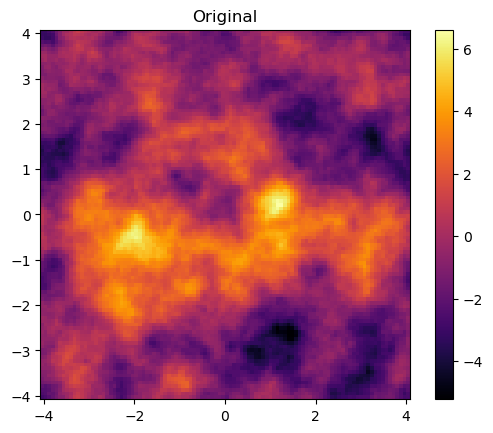

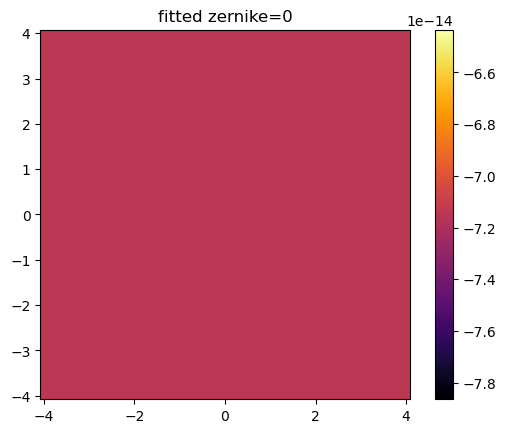

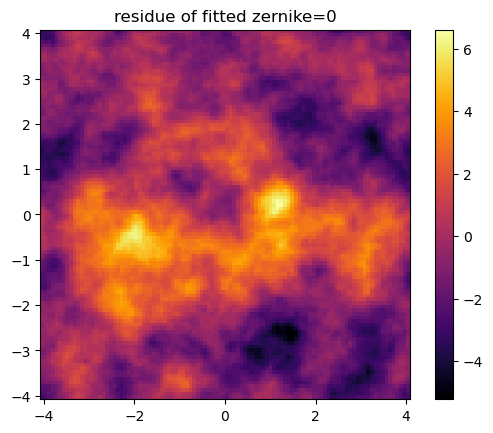

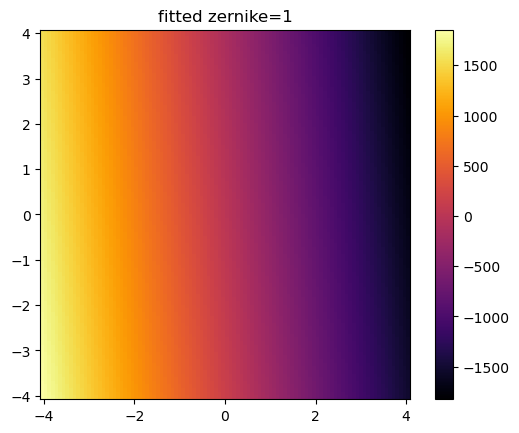

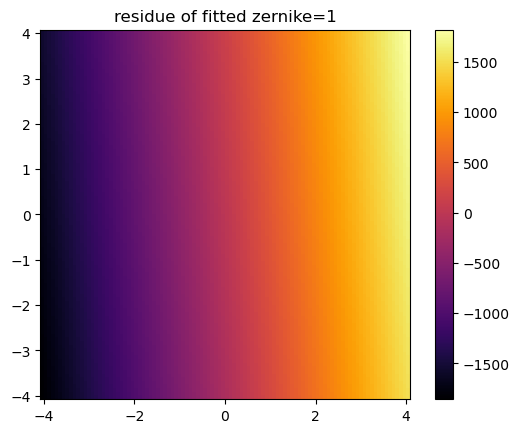

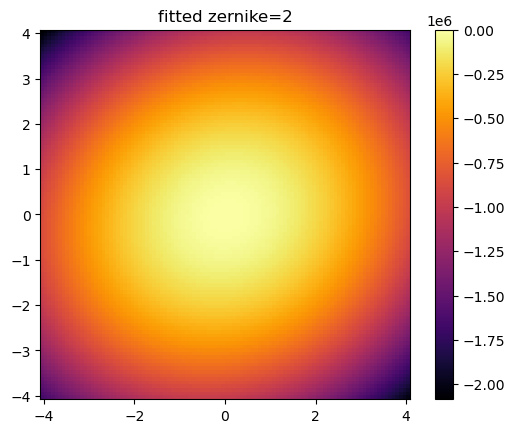

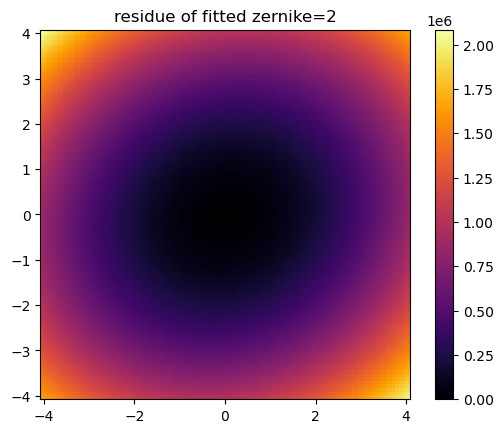

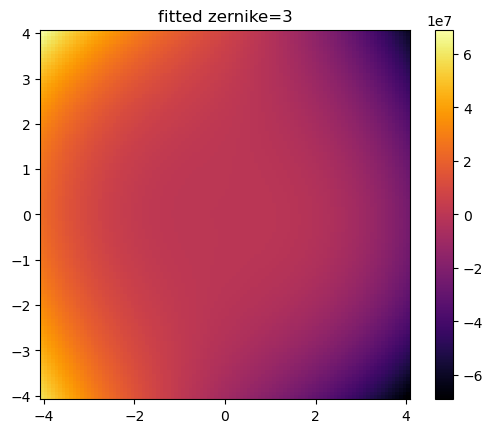

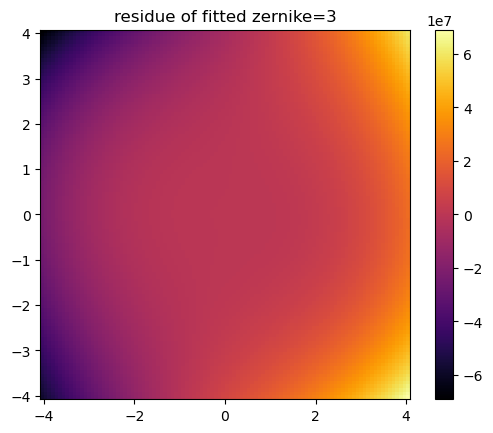

In [24]:
phs0=z00*np.ones(phs.shape)
phs1=(z00*1+zm11*(xx)+z11*(yy))
phs2=(z00*1+zm11*(xx)+z11*(yy)
      +zm22*(xx**2-yy**2)+z02*(-1+2*xx**2+2*yy**2)+z22*(2*xx*yy))
phs3=(z00*1+zm11*(xx)+z11*(yy)
      +zm22*(xx**2-yy**2)+z02*(-1+2*xx**2+2*yy**2)+z22*(2*xx*yy)
      +zm33*(xx**3-3*xx*yy**2)+zm13*(3*xx**3+3*xx*yy**2-2*xx)
      +z13*(3*yy**3+3*xx**2*yy-2*yy)+z33*(-yy**3+3*xx**2*yy))


plt.imshow(phs,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('Original')
plt.show()

plt.imshow(phs0,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('fitted zernike=0')
plt.show()

plt.imshow(phs-phs0,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('residue of fitted zernike=0')
plt.show()

plt.imshow(phs1,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('fitted zernike=1')
plt.show()

plt.imshow(phs-phs1,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('residue of fitted zernike=1')
plt.show()

plt.imshow(phs2,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('fitted zernike=2')
plt.show()

plt.imshow(phs-phs2,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('residue of fitted zernike=2')
plt.show()

plt.imshow(phs3,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('fitted zernike=3')
plt.show()

plt.imshow(phs-phs3,cmap='inferno',extent=[-N/2*delta,N/2*delta,-N/2*delta,N/2*delta])
plt.colorbar()
plt.title('residue of fitted zernike=3')
plt.show()

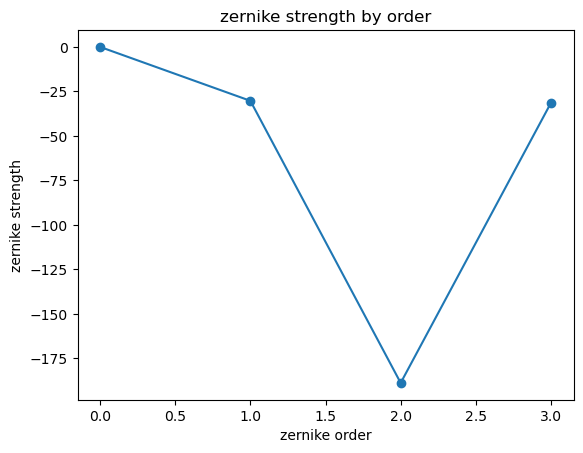

In [25]:
z0=z00
z1=zm11+z11
z2=zm22+z02+z22
z3=zm33+zm13+z13+z33

plt.plot([0,1,2,3],[z0,z1,z2,z3],marker='o')
plt.title('zernike strength by order')
plt.xlabel('zernike order')
plt.ylabel('zernike strength')
plt.show()